# Kidney Stone Second Reader

**Pain point.** On a non-contrast CT for suspected renal colic, stones are tiny (median about 11 px in these slices) and often come in groups: half the slices here hold two or more. The first stone is easy to see; the second and third are easy to miss, and a missed stone changes management.

**User.** The radiologist or ER doctor reading the scan, often on a night shift.

**What the user does with it.**
1. Opens a coronal slice.
2. Sees every candidate stone boxed and numbered, with a confidence score.
3. Accepts or rejects each box. Low-confidence boxes are flagged orange: *please look closer*.

The system is a **second reader**. It proposes; the doctor decides.

**What makes this project different.** The public split of this dataset puts slices from the same CT examination into both train and test. We measure how much that inflates the score, then report the honest number on a split by scan session, at an operating point a doctor would choose.

**Before you run.** Runtime → Change runtime type → **T4 GPU**. Put `kidney.zip` in `MyDrive/kidney_capstone/`. The first run trains two models (about 30 to 45 minutes). Later runs load the saved weights from Drive and skip training, so on presentation day *Run all* takes a few minutes.

In [1]:
!pip -q install ultralytics gradio
from google.colab import drive
drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 618.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 10.8 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
from pathlib import Path
import random, shutil, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

DRIVE = Path('/content/drive/MyDrive/kidney_capstone')
WORK = Path('/content/work')
EPOCHS, IMGSZ, SEED = 50, 640, 0
TARGET_SENSITIVITY = 0.90   # the operating point: find at least 90% of stones on validation
REVIEW_BELOW = 0.50         # boxes under this confidence are flagged for a closer look
SESSION_GAP_S = 60          # slices acquired less than this many seconds apart belong to one scan session

DATA = WORK / 'kidney'
if not DATA.exists():
    with zipfile.ZipFile(DRIVE / 'kidney.zip') as z:
        z.extractall(WORK)

## 1. Data audit: what are we actually looking at?

Each file is one **slice**: a 2D coronal non-contrast CT crop around the kidneys, with boxes around every **stone**. Roboflow stored two augmented copies (flip, ±10° rotation) of every training slice, so we group files by their source UID first.

Slice UIDs carry the acquisition time (the 7th field starts with .NET ticks). Slices acquired seconds apart come from one CT examination: a **scan session**, our stand-in for a patient.

In [3]:
W, H = 391, 320  # every slice in this dataset has this size

def source_uid(path):
    return path.name.split('_png_jpg')[0]

def acquired_at(uid):
    # .NET ticks: 100 ns intervals since 0001-01-01
    return int(uid.split('-')[6][:18]) / 1e7

def read_stones(label_path):
    rows = [line.split() for line in Path(label_path).read_text().splitlines() if line.strip()]
    return [tuple(map(float, r[1:5])) for r in rows]

files = pd.DataFrame([
    {'uid': source_uid(p), 'rf_split': split, 'image': p, 'label': p.parent.parent / 'labels' / f'{p.stem}.txt'}
    for split in ['train', 'valid', 'test']
    for p in sorted((DATA / split / 'images').glob('*.jpg'))
])
assert files.groupby('uid').rf_split.nunique().max() == 1, 'a source slice appears in two Roboflow splits'

slices = (files.groupby('uid')
          .agg(rf_split=('rf_split', 'first'), images=('image', list), labels=('label', list))
          .reset_index())
slices['t'] = slices.uid.map(acquired_at)
slices = slices.sort_values('t').reset_index(drop=True)
slices['session'] = (slices.t.diff() > SESSION_GAP_S).cumsum()
slices['n_stones'] = slices.labels.map(lambda ls: len(read_stones(ls[0])))
train_sessions = set(slices.session[slices.rf_split == 'train'])
slices['leaked'] = (slices.rf_split != 'train') & slices.session.isin(train_sessions)

spanning = slices.groupby('session').rf_split.nunique().gt(1)
print(f'{len(files)} files = {len(slices)} unique slices from {slices.session.nunique()} scan sessions')
print(f'slices with no stone: {(slices.n_stones == 0).sum()}')
print(f'scan sessions spanning more than one Roboflow split: {spanning.sum()} of {len(spanning)}')
print('session count is stable across gap choices:',
      {gap: int((slices.t.diff() > gap).sum() + 1) for gap in [5, 30, 60, 120]})
display(slices.groupby('rf_split').agg(slices=('uid', 'size'), leaked_slices=('leaked', 'sum'), stones=('n_stones', 'sum')))

1300 files = 778 unique slices from 256 scan sessions
slices with no stone: 1
scan sessions spanning more than one Roboflow split: 93 of 256
session count is stable across gap choices: {5: 256, 30: 256, 60: 256, 120: 256}


,slices,leaked_slices,stones
rf_split,,,
test,123,68,224
train,532,0,1150
valid,123,68,325


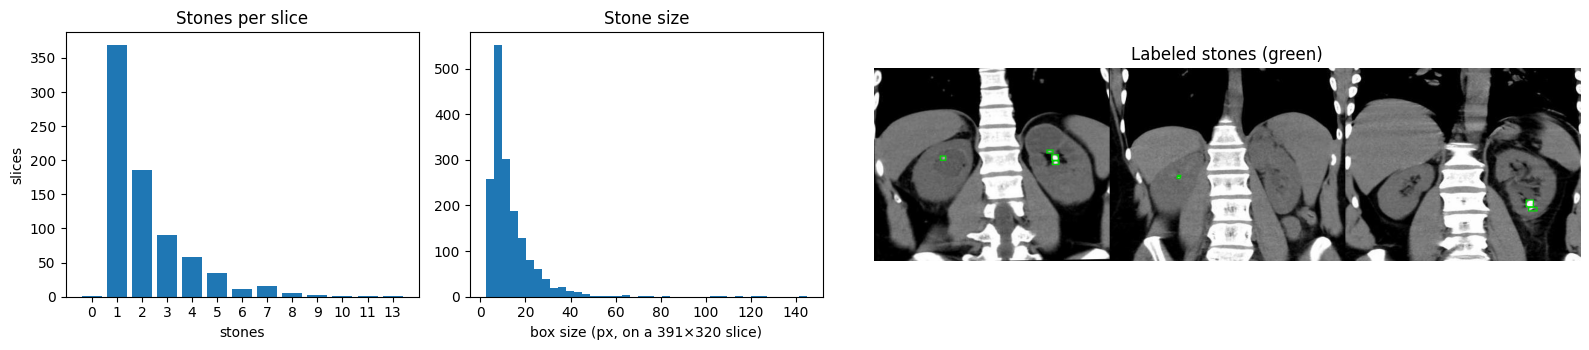

In [4]:
def to_px(box, size):
    cx, cy, w, h = box
    return ((cx - w / 2) * size[0], (cy - h / 2) * size[1], (cx + w / 2) * size[0], (cy + h / 2) * size[1])

def draw(image, stones=(), dets=()):
    """Green: labeled stones. Red: confident detections. Orange: detections to look at closer. dets are (cx, cy, w, h, conf)."""
    im = image.convert('RGB')
    d = ImageDraw.Draw(im)
    for box in stones:
        d.rectangle(to_px(box, im.size), outline=(0, 220, 0), width=2)
    for i, (*box, conf) in enumerate(dets, 1):
        x0, y0, x1, y1 = to_px(box, im.size)
        color = (255, 40, 40) if conf >= REVIEW_BELOW else (255, 165, 0)
        d.rectangle((x0 - 2, y0 - 2, x1 + 2, y1 + 2), outline=color, width=2)
        d.text((x1 + 3, y0 - 10), str(i), fill=color)
    return im

per_slice = slices.n_stones.value_counts().sort_index()
sizes_px = [np.sqrt(w * W * h * H) for ls in slices.labels for _, _, w, h in read_stones(ls[0])]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={'width_ratios': [1, 1, 2]})
ax[0].bar(per_slice.index.astype(str), per_slice.values); ax[0].set(title='Stones per slice', xlabel='stones', ylabel='slices')
ax[1].hist(sizes_px, bins=40); ax[1].set(title='Stone size', xlabel='box size (px, on a 391×320 slice)')
sample = slices[slices.n_stones >= 2].sample(3, random_state=SEED)
ax[2].imshow(np.hstack([np.asarray(draw(Image.open(r.images[0]), read_stones(r.labels[0]))) for r in sample.itertuples()]))
ax[2].set(title='Labeled stones (green)'); ax[2].axis('off')
plt.tight_layout(); plt.show()

## 2. Two ways to split

* **Model A** trains on the Roboflow split as published. We score it separately on **leaked slices** (their scan session also has slices in training) and **clean slices** (it does not). Same model, same test set: the gap is the leakage effect.
* **Model B** trains on a split by scan session (70/15/15), so every test slice comes from an examination the model has never seen. This is the **headline number**.

Training slices keep both augmented copies. Validation and test keep one copy per slice, so no slice is counted twice.

In [5]:
sessions = sorted(slices.session.unique())
random.Random(SEED).shuffle(sessions)
cut1, cut2 = int(0.70 * len(sessions)), int(0.85 * len(sessions))
session_split = {s: 'train' for s in sessions[:cut1]} | {s: 'valid' for s in sessions[cut1:cut2]} | {s: 'test' for s in sessions[cut2:]}
slices['ss_split'] = slices.session.map(session_split)

def yaml_for(root, name, val, test):
    path = root / f'{name}.yaml'
    path.write_text(f"path: {root}\ntrain: train/images\nval: {val}\ntest: {test}\nnames: ['stone']\n")
    return path

def materialize(root, split_col):
    shutil.rmtree(root, ignore_errors=True)
    for split, group in slices.groupby(split_col):
        for sub in ['images', 'labels']:
            (root / split / sub).mkdir(parents=True)
        for r in group.itertuples():
            keep = len(r.images) if split == 'train' else 1
            for img, lab in list(zip(r.images, r.labels))[:keep]:
                shutil.copy(img, root / split / 'images' / img.name)
                shutil.copy(lab, root / split / 'labels' / lab.name)
    return yaml_for(root, 'data', 'valid/images', 'test/images')

def subset_yaml(root, name, rows):
    listing = root / f'{name}.txt'
    listing.write_text('\n'.join(str(root / 'test' / 'images' / r.images[0].name) for r in rows.itertuples()))
    return yaml_for(root, name, listing, listing)

ROOT = {'A': WORK / 'split_roboflow', 'B': WORK / 'split_session'}
DATA_YAML = {'A': materialize(ROOT['A'], 'rf_split'), 'B': materialize(ROOT['B'], 'ss_split')}
A_test = slices[slices.rf_split == 'test']
DATA_YAML['A_leaked'] = subset_yaml(ROOT['A'], 'test_leaked', A_test[A_test.leaked])
DATA_YAML['A_clean'] = subset_yaml(ROOT['A'], 'test_clean', A_test[~A_test.leaked])

assert not set(slices.session[slices.ss_split == 'train']) & set(slices.session[slices.ss_split != 'train'])
display(slices.groupby('ss_split').agg(sessions=('session', 'nunique'), slices=('uid', 'size'), stones=('n_stones', 'sum')))

,sessions,slices,stones
ss_split,,,
test,39,120,248
train,179,554,1221
valid,38,104,230


## 3. Train

YOLOv8s, pretrained on COCO, at 640 px so the tiny stones cover more pixels. Training runs only when the weights are not already in Drive, so re-running the notebook is safe and fast.

In [6]:
from ultralytics import YOLO

WEIGHTS = {'A': DRIVE / 'model_A_roboflow_split.pt', 'B': DRIVE / 'model_B_session_split.pt'}

def trained(key):
    if not WEIGHTS[key].exists():
        model = YOLO('yolov8s.pt')
        model.train(data=str(DATA_YAML[key]), epochs=EPOCHS, imgsz=IMGSZ, batch=16, seed=SEED,
                    project=str(WORK / 'runs'), name=key, exist_ok=True)
        shutil.copy(model.trainer.best, WEIGHTS[key])
    return YOLO(str(WEIGHTS[key]))

models = {key: trained(key) for key in ['A', 'B']}

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/split_roboflow/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fracti

In [7]:
def detections(model, rows):
    out = []
    for r in rows.itertuples():
        result = model.predict(str(r.images[0]), imgsz=IMGSZ, conf=0.001, verbose=False)[0]
        for (cx, cy, w, h), conf in zip(result.boxes.xywhn.tolist(), result.boxes.conf.tolist()):
            out.append({'uid': r.uid, 'conf': conf, 'cx': cx, 'cy': cy, 'w': w, 'h': h})
    return pd.DataFrame(out, columns=['uid', 'conf', 'cx', 'cy', 'w', 'h'])

def map50(key, yaml):
    return models[key].val(data=str(yaml), split='test', imgsz=IMGSZ, plots=False, verbose=False).box.map50

## 4. Evaluate the way a doctor would

* A **hit** is a detection whose center falls inside a labeled stone. On an 11 px stone, a box shifted 3 px fails the usual IoU ≥ 0.5 test, yet any doctor would say *that's the stone*.
* **Stone sensitivity** is the share of labeled stones with a hit: *of all the stones there, how many did it point at?*
* **False alarms per slice** is how many boxes the doctor has to dismiss on each slice.
* **All stones found** is the share of slices where not a single stone was missed.
* The **operating point** is the highest threshold that still finds 90% of stones *on validation*. Test never touches the choice.
* The 95% interval resamples whole scan sessions, because stones from one patient are not independent.
* **mAP50** is the standard ML metric (IoU ≥ 0.5), reported so the ML side is complete.

In [8]:
def stone_table(rows):
    return pd.DataFrame([{'uid': r.uid, 'session': r.session, 'cx': cx, 'cy': cy, 'w': w, 'h': h}
                         for r in rows.itertuples() for cx, cy, w, h in read_stones(r.labels[0])])

def match(stones, dets):
    """Adds stones.best_conf (highest confidence of any hit on the stone, 0 if none) and dets.hit."""
    stones, dets = stones.reset_index(drop=True), dets.reset_index(drop=True)
    pairs = stones.reset_index().merge(dets.reset_index(), on='uid', suffixes=('_s', '_d'))
    inside = ((pairs.cx_d - pairs.cx_s).abs() <= pairs.w_s / 2) & ((pairs.cy_d - pairs.cy_s).abs() <= pairs.h_s / 2)
    pairs = pairs[inside]
    stones['best_conf'] = pairs.groupby('index_s').conf.max().reindex(stones.index, fill_value=0.0)
    dets['hit'] = dets.index.isin(pairs.index_d)
    return stones, dets

def at(stones, dets, n_slices, t):
    found = stones.best_conf >= t
    return {'threshold': t,
            'stone_sensitivity': found.mean(),
            'false_alarms_per_slice': ((dets.conf >= t) & ~dets.hit).sum() / n_slices,
            'all_stones_found': found.groupby(stones.uid).all().mean()}

def operating_point(stones, target):
    confs = np.sort(stones.best_conf.to_numpy())[::-1]
    k = int(np.ceil(round(target * len(confs), 6)))
    return max(confs[k - 1], 0.001)

def sensitivity_ci(stones, t, n=2000):
    per_session = stones.assign(found=stones.best_conf >= t).groupby('session').found.agg(['sum', 'size'])
    pick = np.random.default_rng(SEED).integers(0, len(per_session), (n, len(per_session)))
    rates = per_session['sum'].to_numpy()[pick].sum(1) / per_session['size'].to_numpy()[pick].sum(1)
    return np.percentile(rates, [2.5, 97.5])

rows_of = {'A': (slices[slices.rf_split == 'valid'], A_test),
           'B': (slices[slices.ss_split == 'valid'], slices[slices.ss_split == 'test'])}
op, evals = {}, {}
for key, (val_rows, test_rows) in rows_of.items():
    val_stones, _ = match(stone_table(val_rows), detections(models[key], val_rows))
    op[key] = operating_point(val_stones, TARGET_SENSITIVITY)
    print(f'Model {key}: threshold {op[key]:.3f} finds {(val_stones.best_conf >= op[key]).mean():.0%} of validation stones')
    evals[key] = match(stone_table(test_rows), detections(models[key], test_rows))

def only(key, rows):
    stones, dets = evals[key]
    return stones[stones.uid.isin(rows.uid)], dets[dets.uid.isin(rows.uid)], len(rows)

views = {
    'A · all Roboflow test': ('A', A_test, DATA_YAML['A']),
    'A · leaked slices': ('A', A_test[A_test.leaked], DATA_YAML['A_leaked']),
    'A · clean slices': ('A', A_test[~A_test.leaked], DATA_YAML['A_clean']),
    'B · session-split test (headline)': ('B', rows_of['B'][1], DATA_YAML['B']),
}
results = []
for name, (key, rows, yaml) in views.items():
    stones, dets, n = only(key, rows)
    lo, hi = sensitivity_ci(stones, op[key])
    results.append({'evaluation': name, 'slices': n, 'stones': len(stones), 'mAP50': map50(key, yaml),
                    **at(stones, dets, n, op[key]), 'sensitivity_95ci': f'{lo:.2f} to {hi:.2f}'})
results = pd.DataFrame(results).set_index('evaluation')
display(results.round(3))

Model A: threshold 0.225 finds 90% of validation stones
Model B: threshold 0.020 finds 90% of validation stones
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 12.7±6.1 MB/s, size: 15.6 KB)
val: Scanning /content/work/split_roboflow/test/labels... 123 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 123/123 1.5Kit/s 0.1s
val: New cache created: /content/work/split_roboflow/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.3it/s 1.9s
                   all        123        224       0.82      0.737      0.748      0.334
Speed: 0.8ms preprocess, 9.6ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters

,slices,stones,mAP50,threshold,stone_sensitivity,false_alarms_per_slice,all_stones_found,sensitivity_95ci
evaluation,,,,,,,,
A · all Roboflow test,123,224,0.748,0.225,0.902,0.138,0.829,0.86 to 0.94
A · leaked slices,68,145,0.781,0.225,0.903,0.221,0.794,0.85 to 0.94
A · clean slices,55,79,0.711,0.225,0.899,0.036,0.873,0.84 to 0.97
B · session-split test (headline),120,248,0.732,0.020,0.948,0.733,0.908,0.92 to 0.98


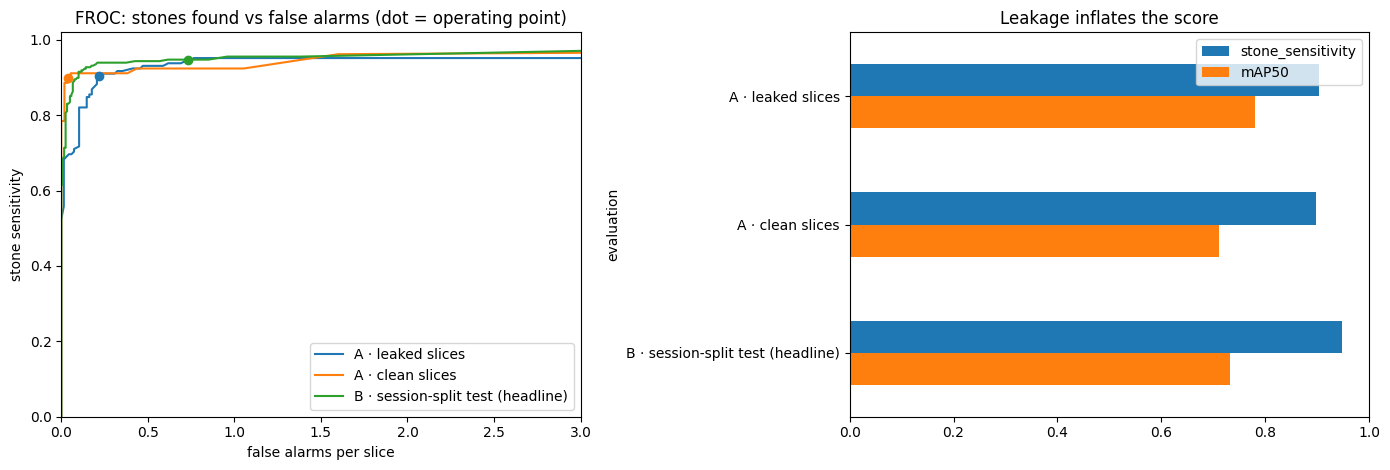

In [9]:
grid = np.linspace(0.001, 0.95, 200)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for name in ['A · leaked slices', 'A · clean slices', 'B · session-split test (headline)']:
    key, rows, _ = views[name]
    stones, dets, n = only(key, rows)
    curve = pd.DataFrame([at(stones, dets, n, t) for t in grid])
    line, = ax[0].plot(curve.false_alarms_per_slice, curve.stone_sensitivity, label=name)
    point = at(stones, dets, n, op[key])
    ax[0].scatter(point['false_alarms_per_slice'], point['stone_sensitivity'], color=line.get_color(), zorder=3)
ax[0].set(title='FROC: stones found vs false alarms (dot = operating point)', xlabel='false alarms per slice',
          ylabel='stone sensitivity', xlim=(0, 3), ylim=(0, 1.02))
ax[0].legend(loc='lower right')
results[['stone_sensitivity', 'mAP50']].drop('A · all Roboflow test').plot.barh(ax=ax[1])
ax[1].set(title='Leakage inflates the score', xlim=(0, 1)); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

## 5. Where does it fail?

Is it the small stones? Is it slices crowded with stones? Then look at the misses and the confident false alarms with your own eyes.

In [10]:
stones, dets = evals['B']
t = op['B']
stones = stones.assign(size_px=np.sqrt(stones.w * W * stones.h * H), found=stones.best_conf >= t)
stones['size_group'] = pd.qcut(stones.size_px.rank(method='first'), 3, labels=['small', 'medium', 'large'])
display(stones.groupby('size_group', observed=True)
        .agg(stones=('found', 'size'), median_px=('size_px', 'median'), stone_sensitivity=('found', 'mean')).round(2))
crowd = stones.groupby('uid').agg(n=('found', 'size'), all_found=('found', 'all'))
display(crowd.groupby(pd.cut(crowd.n, [0, 1, 2, 4, 99], labels=['1 stone', '2 stones', '3-4 stones', '5+ stones']), observed=True)
        .all_found.agg(slices='size', all_stones_found='mean').round(2))

,stones,median_px,stone_sensitivity
size_group,,,
small,83,6.48,0.89
medium,82,10.00,0.96
large,83,19.49,0.99


,slices,all_stones_found
n,,
1 stone,57,1.00
2 stones,33,0.91
3-4 stones,20,0.90
5+ stones,10,0.40


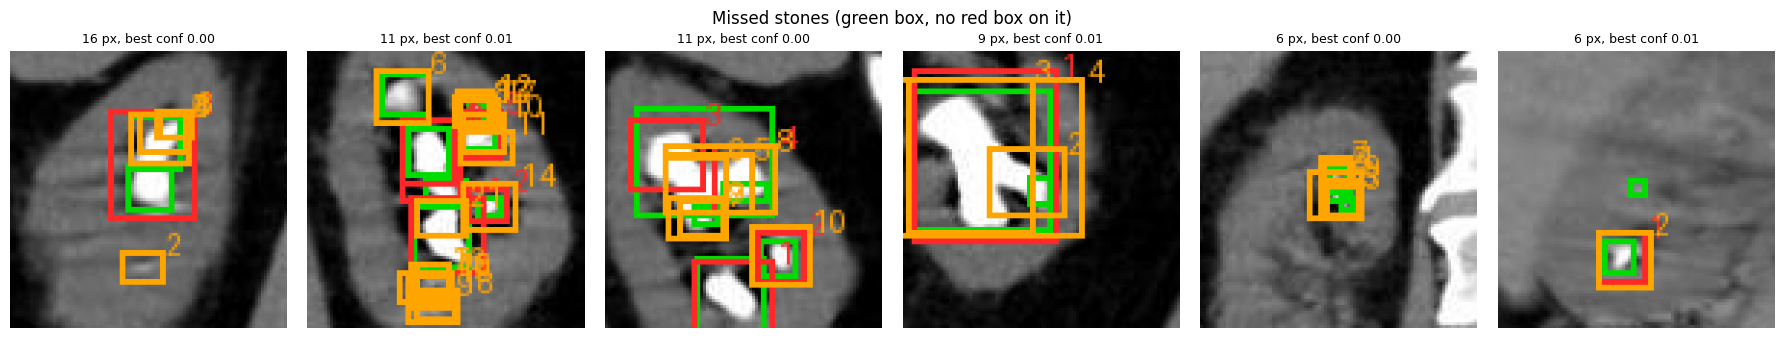

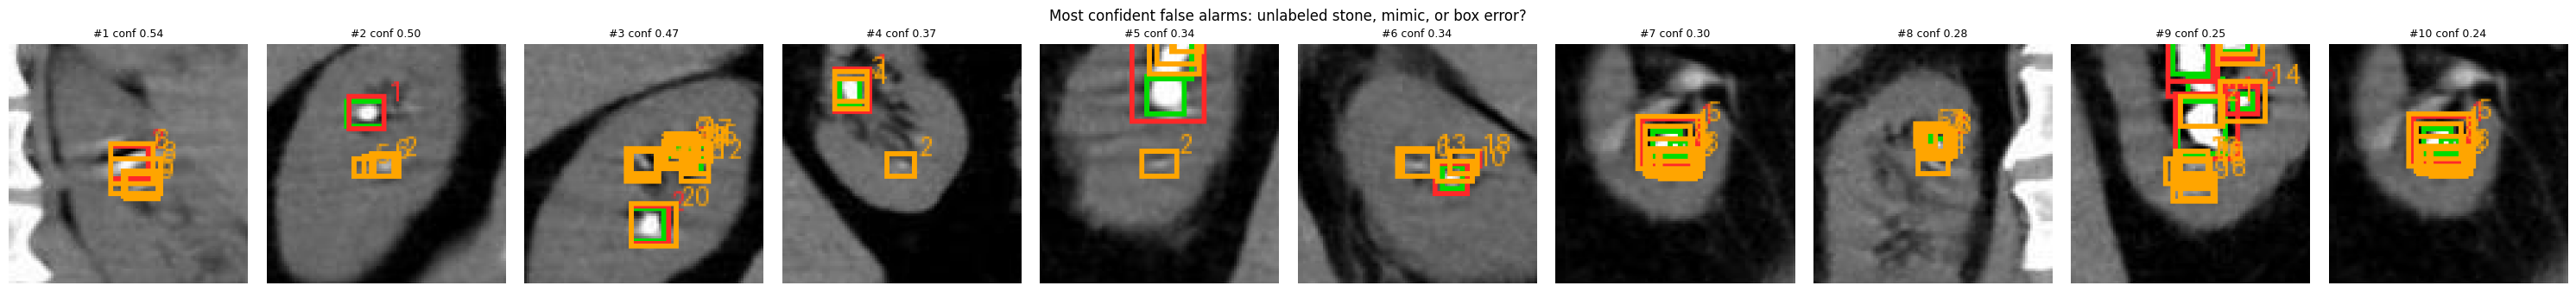

In [11]:
image_of = dict(zip(slices.uid, slices.images.str[0]))
label_of = dict(zip(slices.uid, slices.labels.str[0]))

def zoom(uid, box, conf=None, half=48):
    """The slice around one box, labeled stones in green, detections at the operating point in red/orange."""
    shown = dets[(dets.uid == uid) & (dets.conf >= t)].sort_values('conf', ascending=False)
    im = draw(Image.open(image_of[uid]), read_stones(label_of[uid]), shown[['cx', 'cy', 'w', 'h', 'conf']].itertuples(index=False))
    x, y = box[0] * im.width, box[1] * im.height
    return im.crop((x - half, y - half, x + half, y + half)).resize((288, 288), Image.NEAREST)

def gallery(title, items):
    fig, axes = plt.subplots(1, len(items), figsize=(3 * len(items), 3.4), squeeze=False)
    for a, (img, caption) in zip(axes[0], items):
        a.imshow(img); a.set_title(caption, fontsize=9); a.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

missed = stones[~stones.found].sort_values('size_px', ascending=False).head(6)
gallery('Missed stones (green box, no red box on it)',
        [(zoom(r.uid, (r.cx, r.cy)), f'{r.size_px:.0f} px, best conf {r.best_conf:.2f}') for r in missed.itertuples()])

false_alarms = dets[(dets.conf >= t) & ~dets.hit].sort_values('conf', ascending=False).head(10)
gallery('Most confident false alarms: unlabeled stone, mimic, or box error?',
        [(zoom(r.uid, (r.cx, r.cy)), f'#{i} conf {r.conf:.2f}') for i, r in enumerate(false_alarms.itertuples(), 1)])

### Label audit

Look at each confident false alarm above and pick one category. **Not radiologist-verified.**

| Category | What it looks like |
|---|---|
| Unlabeled stone | Bright, round, inside the kidney's collecting system, but no green box. The model may be right and the label wrong. |
| Stone mimic | A **phlebolith** (calcified pelvic vein, often with a lucent center), a **vascular calcification** along an artery, bowel content, or bone. |
| Box error | The model's box sits next to a green box on the same stone. |

In [12]:
audit = false_alarms[['uid', 'conf']].assign(category='')  # fill in: unlabeled stone / stone mimic / box error
audit.index = range(1, len(audit) + 1)
display(audit)

,uid,conf,category
1,1-3-46-670589-33-1-63715469322363963500001-559...,0.543305,
2,1-3-46-670589-33-1-63706641772866810800001-494...,0.498198,
3,1-3-46-670589-33-1-63706641772833809000001-547...,0.474256,
4,1-3-46-670589-33-1-63724535887338560100001-510...,0.373160,
5,1-3-46-670589-33-1-63714778964380539800001-570...,0.340500,
6,1-3-46-670589-33-1-63706641772833809000001-547...,0.336979,
7,1-3-46-670589-33-1-63714778963981517000001-505...,0.302861,
8,1-3-46-670589-33-1-63741210469290199500001-534...,0.283779,
9,1-3-46-670589-33-1-63714778964147526500001-565...,0.249691,
10,1-3-46-670589-33-1-63714778963981517000001-505...,0.243644,


## 6. Medical interpretation

Read the headline row (Model B) like this.

* **Stone sensitivity at the operating point.** Of every 100 stones on a new patient's slices, about this many get a box. The rest are misses the doctor must still catch alone.
* **False alarms per slice.** This many boxes per slice the doctor has to dismiss. Under about 1 is tolerable for a second reader, while several per slice trains the doctor to ignore the tool.
* **All stones found.** For counting stones (single vs. multiple) this matters more than per-stone sensitivity. One missed stone in a crowded kidney changes the count.
* **Size.** If small stones are missed most, the harm is limited: stones under about 5 mm usually pass on their own. A missed *large* stone is the dangerous error. Sizes here are in pixels, not mm, so this is only a trend.
* **Leakage gap (A leaked vs. A clean).** This is how much a naive evaluation would over-promise to a hospital.

## 7. Before this goes near a real clinic

1. **Specificity is unknown.** Every slice here contains a stone, so we cannot say how often it raises alarms on a healthy patient.
2. **One source.** All scans come from one center on one vendor (Philips), in Turkey, from 2019 to 2020. It needs external validation on other hospitals and scanners.
3. **2D, not 3D.** It sees single slices, while doctors scroll through the whole volume, and one stone spans several slices.
4. **No size in mm.** Pixel spacing was lost in export, so it cannot support decisions about whether a stone will pass or needs a procedure.
5. **Kidney crop only.** Ureteral stones, the ones most likely to cause colic, are out of scope.
6. **Noisy labels.** One unknown annotator, no radiologist consensus. Section 5 shows boxes the labels probably missed.
7. **Stone mimics.** Phleboliths and vascular calcifications can trigger false alarms.
8. **Automation bias and regulation.** Doctors may trust what the model misses. As clinical decision software it is a regulated medical device and needs approval before use.

## 8. Demo: the second reader

Upload a coronal slice or click an example. Red boxes are confident; orange boxes need a closer look. The slider starts at the 90%-sensitivity operating point.

In [13]:
import gradio as gr

def second_reader(image, threshold):
    result = models['B'].predict(image, imgsz=IMGSZ, conf=threshold, verbose=False)[0]
    found = sorted(zip(result.boxes.xywhn.tolist(), result.boxes.conf.tolist()), key=lambda d: -d[1])
    dets = [(*box, conf) for box, conf in found]
    lines = [f'| {i} | {conf:.2f} | {"likely stone" if conf >= REVIEW_BELOW else "look closer"} |' for i, (*_, conf) in enumerate(dets, 1)]
    report = (f'### {len(dets)} candidate stone(s)\n\n| # | confidence | flag |\n|---|---|---|\n' + '\n'.join(lines)
              + '\n\n_Second reader only. Every box needs confirmation by the reading doctor. No box does not mean no stone._')
    return draw(image, dets=dets), report

examples = [[str(p), round(op['B'], 3)] for p in slices[(slices.ss_split == 'test') & (slices.n_stones >= 2)].images.str[0].head(4)]
gr.Interface(
    second_reader,
    [gr.Image(type='pil', label='Coronal non-contrast CT slice'),
     gr.Slider(0.01, 0.9, value=round(op['B'], 3), step=0.01, label='Confidence threshold (starts at the 90% sensitivity operating point)')],
    [gr.Image(label='Candidate stones'), gr.Markdown()],
    examples=examples,
    title='Kidney Stone Second Reader',
).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1ea15423a18703db11.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
